In [1]:
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tc5061_proyecto_equipo5.config import FIGURES_DIR, RAW_DATA_DIR,INTERIM_DATA_DIR, INITIAL_YEAR, END_YEAR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
AZUL, NARANJA, ROJO, GRIS = "#2a78d6","#FF8000", "#e34948",  "#8a8984"

def leer_csv(ruta, **kwargs):
    """Intenta UTF-8 y, si falla, latin-1 (los archivos viejos usan esa codificación)."""
    try:
        return pd.read_csv(ruta, encoding="utf-8", **kwargs), "utf-8"
    except UnicodeDecodeError:
        return pd.read_csv(ruta, encoding="latin-1", **kwargs), "latin-1"

2026-10-17 13:03:21.318 | INFO     | tc5061_proyecto_equipo5.config:<module>:11 - PROJ_ROOT path is: /home/fernandosoft/proyectos/TC5061-Proyecto-Equipo05


# Inventario de archivos

In [2]:
todos = sorted(RAW_DATA_DIR.rglob("*.csv"))
nomenclatura = [p for p in todos if "nomenclatura" in p.name.lower()]
archivos = [p for p in todos if p not in nomenclatura]

print(f"Archivos de viajes: {len(archivos)} ({sum(p.stat().st_size for p in archivos) / 1e9:.2f} GB)")
print(f"Primero: {archivos[0].name} | último: {archivos[-1].name}")
print(f"Nomenclatura: {[p.name for p in nomenclatura]}")

Archivos de viajes: 142 (3.11 GB)
Primero: datos_abiertos_2014_12.csv | último: datos_abiertos_2026_09.csv
Nomenclatura: ['nomenclatura_2026_09.csv']


Parte A - Nomeclatura de estaciones

In [3]:
#Que tiene el archivo de nomeclatura
estaciones, enc = leer_csv(nomenclatura[-1])
print(f"Codificación: {enc} | estaciones: {len(estaciones)} | columnas: {list(estaciones.columns)}")
print(estaciones.dtypes)
estaciones.sample(10, random_state=42)

Codificación: utf-8 | estaciones: 484 | columnas: ['id', 'name', 'latitude', 'longitude', 'dpcapacity']
id              int64
name              str
latitude      float64
longitude     float64
dpcapacity      int64
dtype: object


,id,name,latitude,longitude,dpcapacity
418,442,(GDL-303) Sta. Irene / Av. Lopez Mateos Sur,20.67,-103.39,19
474,510,(ZPN-102) C. Volcán del Colli/V. del Ajusco,20.64,-103.43,15
181,190,(GDL-123) C. Aurelio L. Gallardo / Av. México,20.68,-103.38,11
446,473,(GDL-351) Valentín Gómez Farías / Irineo Paz,20.66,-103.32,11
297,313,(ZPN-057) C. Escultores / Av. Guadalupe,20.66,-103.42,15
148,157,(GDL-090) Calz. Federalismo / C. Durango,20.70,-103.36,23
380,397,(GDL-279) Belen / Av. de los Maestros,20.69,-103.35,19
386,409,(GDL-286) T. V. Gómez /Av. José Maria Morelos,20.68,-103.38,19
479,515,(GDL-295) C. Tarahumaras / Av. Manuel Acuña,20.68,-103.39,15
227,236,(GDL-169) Blvrd. García Barragán/ C. Rio Zapo,20.65,-103.32,23


In [4]:
#Faltan datos o hay repetidos? 
print("Nulos por columna:")
print(estaciones.isna().sum())
print()
print("ids repetidos:", estaciones["id"].duplicated().sum())
print("nombres repetidos:", estaciones["name"].duplicated().sum())
print("coordenadas repetidas:", estaciones[["latitude", "longitude"]].duplicated().sum())


Nulos por columna:
id            0
name          0
latitude      0
longitude     0
dpcapacity    0
dtype: int64

ids repetidos: 0
nombres repetidos: 0
coordenadas repetidas: 2


In [5]:
#Los ids con consecutivos o tienen saltos
ids = estaciones["id"]
print("id minimo:", ids.min(), "| id maximo:", ids.max())
print("ids que faltan dentro del rango:", ids.max() - ids.min() + 1 - ids.nunique())

id minimo: 2 | id maximo: 519
ids que faltan dentro del rango: 34


In [6]:
estaciones["name"].head(15).tolist()

['(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.',
 '(GDL-002) C. Colonias  / Av.  Niños héroes',
 '(GDL-003) C. Vidrio / Av. Chapultepec',
 '(GDL-004) C. Ghilardi /C. Miraflores',
 '(GDL-005) C. San Diego /Calzada Independencia',
 '(GDL-006) C. Venustiano Carranza /C. Reforma',
 '(GDL-007) C. Epigmenio Glez./Av. Cristobal C.',
 '(GDL-008) C. Ignacio Zaragoza / C. J. Angulo',
 '(GDL-009) Calz. Federalismo/ C. J. Angulo',
 '(GDL-010) C. Cruz verde / C. Joaquin Angulo',
 '(GDL-011) C. Garibaldi / C. Frías',
 '(GDL-012) C. Joaquín Angulo / C. Ghilardi',
 '(GDL-013) C. Vidrio  / C. Marsella',
 '(GDL-014) C. J. Angulo/C José Clemente Orozco',
 '(GDL-015) C. Herrera y Cairo /C. Pedro Buzeta']

In [7]:
# Extrae el texto antes del primer guion dentro de un parentesis: (GDL-001) => GDL"
estaciones["prefijo"] = estaciones["name"].str.extract(r"\(\s*([A-Za-z]+)\s*-", expand=False)
print(f"Nombres con prefijo: {estaciones['prefijo'].notna().mean():.0%}")
estaciones["prefijo"].value_counts(dropna=False)

Nombres con prefijo: 100%


prefijo
GDL    356
ZPN    110
TLQ     17
NaN      1
Name: count, dtype: int64

In [8]:
#Capacidad (numero de anclajes)
print(estaciones["dpcapacity"].value_counts().sort_index())

dpcapacity
0       4
11     54
15    201
19    175
23     39
27      2
30      1
31      7
39      1
Name: count, dtype: int64


In [9]:
# Estaciones con capacidad 0
estaciones[estaciones["dpcapacity"] == 0]

,id,name,latitude,longitude,dpcapacity,prefijo
94,99,ex-(ZPN-009) C. Del Corral / C. Nicolás Bravo,20.69,-103.33,0,ZPN
104,109,ex-(ZPN-019) C. Cabecera Mpal. Juan Manuel / C.,20.72,-103.39,0,ZPN
111,116,ex-(ZPN-026) C. 16 Sep. / C. Fray A. de Segovia,20.69,-103.33,0,ZPN
129,138,ex-(ZPN-044),20.70,-103.36,0,ZPN


In [10]:
# Las de mayor capacidad
estaciones.sort_values("dpcapacity", ascending=False).head(10)

,id,name,latitude,longitude,dpcapacity,prefijo
48,51,(GDL-049) Lopez Cotilla / Penitenciaría,20.67,-103.36,39,GDL
270,281,(GDL-208) Av. España / Av. Federalismo,20.66,-103.36,31,GDL
252,263,(GDL-190) C. Anahuac / Av. Revolución,20.67,-103.34,31,GDL
277,288,(ZPN-048) Av. J. Parres Arias / Prol. López C,20.73,-103.39,31,ZPN
280,291,(ZPN-051) Av. Periférico G. Morín / Av. J. Pa,20.74,-103.38,31,ZPN
282,293,(ZPN-053) Prol. Laureles / Av. Periférico G.,20.74,-103.38,31,ZPN
272,283,(GDL-210) Av. Washington / Calz. Independenci,20.66,-103.35,31,GDL
260,271,(GDL-198) Av. Alcalde / C. Hospital,20.69,-103.35,31,GDL
254,265,(GDL-192) Calle A1 / Av. Manuel A. Camacho,20.71,-103.37,30,GDL
62,65,(GDL-063) C. Colonias / C. López Cotilla,20.67,-103.37,27,GDL


In [11]:
if estaciones["prefijo"].notna().any():
    display(estaciones.groupby("prefijo")["dpcapacity"].agg(["count", "sum", "mean", "min", "max"]))

,count,sum,mean,min,max
prefijo,,,,,
GDL,356,6119,17.19,11,39
TLQ,17,259,15.24,15,19
ZPN,110,1778,16.16,0,31


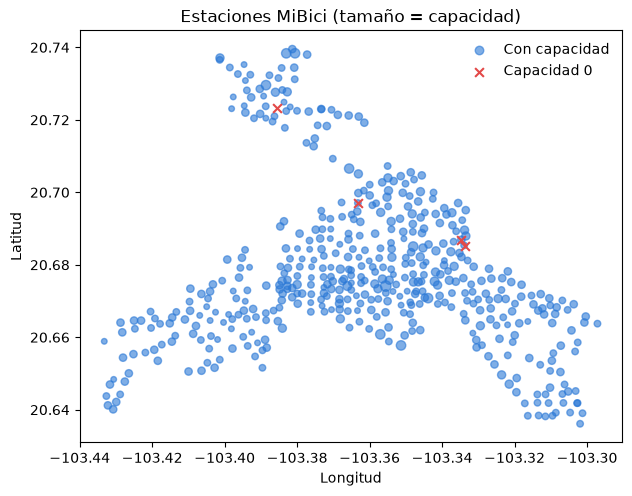

In [12]:
#Ubicacion
fig, ax = plt.subplots(figsize=(7, 7))
cero = estaciones["dpcapacity"] == 0
ax.scatter(estaciones.loc[~cero, "longitude"], estaciones.loc[~cero, "latitude"],
           s=estaciones.loc[~cero, "dpcapacity"] * 1.5, alpha=0.6, color=AZUL, label="Con capacidad")
ax.scatter(estaciones.loc[cero, "longitude"], estaciones.loc[cero, "latitude"],
           s=40, color=ROJO, marker="x", label="Capacidad 0")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Estaciones MiBici (tamaño = capacidad)")
ax.set_aspect("equal")
ax.legend(frameon=False)
fig.savefig(FIGURES_DIR / "eda_estaciones.png", bbox_inches="tight")
plt.show()

In [13]:
# uv add folium
import folium

ESRI = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"
ATRIBUCION = "Mapa base: Esri, HERE, Garmin, © OpenStreetMap contributors"

mapa = folium.Map(location=[estaciones["latitude"].mean(), estaciones["longitude"].mean()],
                  zoom_start=12, tiles=ESRI, attr=ATRIBUCION)
for _, e in estaciones.iterrows():
    sin_cap = e["dpcapacity"] == 0
    folium.CircleMarker(
        location=[e["latitude"], e["longitude"]],
        radius=3 if sin_cap else e["dpcapacity"] / 3,
        color=ROJO if sin_cap else AZUL, fill=True, fill_opacity=0.7, weight=1,
        popup=f"{e['id']} - {e['name']}<br>Capacidad: {e['dpcapacity']}",
        tooltip=e["name"],
    ).add_to(mapa)
mapa.save(FIGURES_DIR / "eda_estaciones_mapa.html")
# mapa

### Conclusiones de la nomenclatura
- Estaciones: 484
- Datos faltantes / repetidos: 0 faltantes, 2 coordenadas repetidas
- Ids: minimo 2 | maximo 519 , faltan 34 en el rango
- Nombres y zonas: Guadalajara 356, zapopan 110, tlaquepaque 17, NA 1
- Capacidad:  1 estacion con capacidad de 39 anclajes,7 estaciones con 31 anclajes ... estaciones con capacidad 0: 4

# Parte B - Viajes de un rango de meses

In [14]:
# B1 => Elegir rango y cargar
def mes_del_archivo(ruta):
    """'datos_abiertos_2025_03.csv' -> '2025-03'."""
    """ regex: ano que empiece con 20 seguido de _ o -m y de uno a dos digitos para el mes """
    m = re.search(r"(20\d{2})[_\-](\d{1,2})", ruta.stem)
    return f"{m.group(1)}-{int(m.group(2)):02d}" if m else None


def normalizar(nombre):
    """'Inicio del viaje' / 'Inicio_del_viaje' -> 'inicio_del_viaje' (sin acentos)."""
    """ Limpia los nombres de columna para que sean iguales todos los anos"""
    nombre = unicodedata.normalize("NFKD", str(nombre)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", nombre.lower()).strip("_")


meses_disponibles = sorted(m for p in archivos if (m := mes_del_archivo(p)))
print(f"Meses disponibles: {meses_disponibles[0]} a {meses_disponibles[-1]}")

INICIO, FIN = meses_disponibles[0], meses_disponibles[-1]
seleccion = [p for p in archivos if (m := mes_del_archivo(p)) and INICIO <= m <= FIN]
print(f"Rango: {INICIO} a {FIN} ({len(seleccion)} archivos)")

Meses disponibles: 2014-12 a 2026-09
Rango: 2014-12 a 2026-09 (142 archivos)


In [15]:
CACHE = INTERIM_DATA_DIR / "viajes_eda.parquet"

FORMATOS = ["%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M", "%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M",
            "%m/%d/%Y %H:%M:%S", "%m/%d/%Y %H:%M"]


def a_fecha(serie, mes):
    """Prueba varios formatos y se queda con el que deja más fechas dentro del mes del archivo.
    Evita que '05/01/2015' se lea como 1 de mayo."""
    mejor, mejor_ok = None, -1
    for fmt in FORMATOS:
        f = pd.to_datetime(serie.str.strip(), format=fmt, errors="coerce")
        ok = (f.dt.strftime("%Y-%m") == mes).mean()
        if ok > mejor_ok:
            mejor, mejor_ok = f, ok
    return mejor


def columna(d, palabra):
    return next(c for c in d.columns if palabra in c)


if CACHE.exists():
    viajes = pd.read_parquet(CACHE)
    print(f"Cargado del caché: {len(viajes):,} viajes")
else:
    partes = []
    for ruta in seleccion:
        mes = mes_del_archivo(ruta)
        d, enc = leer_csv(ruta, dtype=str)
        d.columns = [normalizar(c) for c in d.columns]
        inicio = a_fecha(d[columna(d, "inicio")], mes)
        fin = a_fecha(d[columna(d, "fin")], mes)
        partes.append(pd.DataFrame({            # solo columnas útiles, ya con su tipo (sin datos personales)
            "viaje_id": pd.to_numeric(d[columna(d, "viaje")], errors="coerce").astype("Int64"),
            "inicio": inicio,
            "duracion_min": ((fin - inicio).dt.total_seconds() / 60).astype("float32"),
            "origen": pd.to_numeric(d[columna(d, "origen")], errors="coerce").astype("Int32"),
            "destino": pd.to_numeric(d[columna(d, "destino")], errors="coerce").astype("Int32"),
            "mes_archivo": mes,
        }))
        print(f"{ruta.name}: {len(d):,} viajes | {enc} | fuera del mes: {(inicio.dt.strftime('%Y-%m') != mes).mean():.1%}")
    viajes = pd.concat(partes, ignore_index=True)
    del partes
    viajes["mes_archivo"] = viajes["mes_archivo"].astype("category")
    viajes.to_parquet(CACHE, index=False)
    print(f"Guardado en {CACHE}")


print(f"Total: {len(viajes):,} viajes | memoria: {viajes.memory_usage(deep=True).sum() / 1e6:.0f} MB")

Cargado del caché: 39,078,840 viajes
Total: 39,078,840 viajes | memoria: 1290 MB


In [16]:
#B2 => Nulos y duplicados
print(viajes.isna().sum())
print()
print("filas duplicadas:", viajes.duplicated().sum())
col_id = next((c for c in viajes.columns if "viaje" in c and "id" in c), None)
if col_id:
    print(f"ids de viaje repetidos ({col_id}):", viajes[col_id].duplicated().sum())

viaje_id        0
inicio          0
duracion_min    0
origen          0
destino         0
mes_archivo     0
dtype: int64

filas duplicadas: 758
ids de viaje repetidos (viaje_id): 758


In [17]:
# Las fechas ya se convirtieron al cargar (cada archivo con su formato).
# Aquí solo se revisa que estén bien y cómo es la duración.
fuera = viajes["inicio"].dt.strftime("%Y-%m") != viajes["mes_archivo"].astype(str)
print(f"Fechas de inicio inválidas: {viajes['inicio'].isna().sum():,}")
print(f"Viajes fuera del mes de su archivo: {fuera.mean():.2%}")
viajes["duracion_min"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

Fechas de inicio inválidas: 0
Viajes fuera del mes de su archivo: 0.00%


count   39,078,840.00
mean            14.41
std            759.93
min              0.00
1%               0.23
5%               2.15
25%              5.73
50%              9.42
75%             14.68
95%             24.12
99%             33.08
max        629,228.75
Name: duracion_min, dtype: float64

Duracion negativa o cero: 0.14%
Menos de 1 minuto:        3.11%
Mas de 30 min:           1.57%
Mas de 180 min:           0.04%


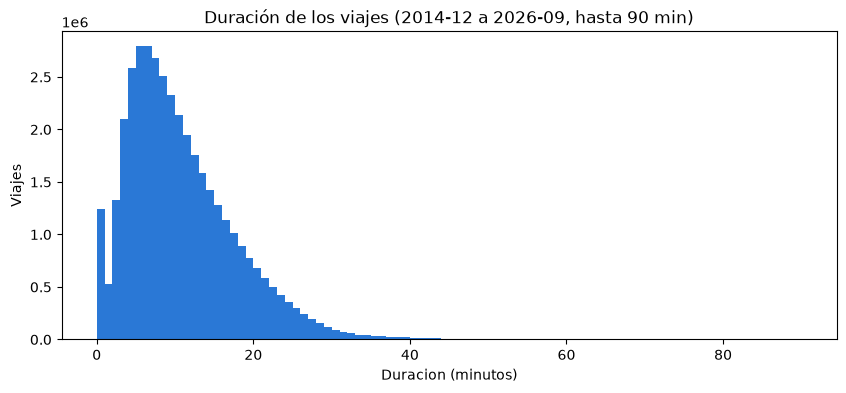

In [18]:
d = viajes["duracion_min"]
print(f"Duracion negativa o cero: {(d <= 0).mean():.2%}")
print(f"Menos de 1 minuto:        {((d > 0) & (d < 1)).mean():.2%}")
print(f"Mas de 30 min:           {(d > 30).mean():.2%}")
print(f"Mas de 180 min:           {(d > 180).mean():.2%}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(d[(d > 0) & (d <= 90)], bins=90, color=AZUL)
ax.set_xlabel("Duracion (minutos)")
ax.set_ylabel("Viajes")
ax.set_title(f"Duración de los viajes ({INICIO} a {FIN}, hasta 90 min)")
fig.savefig(FIGURES_DIR / "eda_duracion.png", bbox_inches="tight")

plt.show()

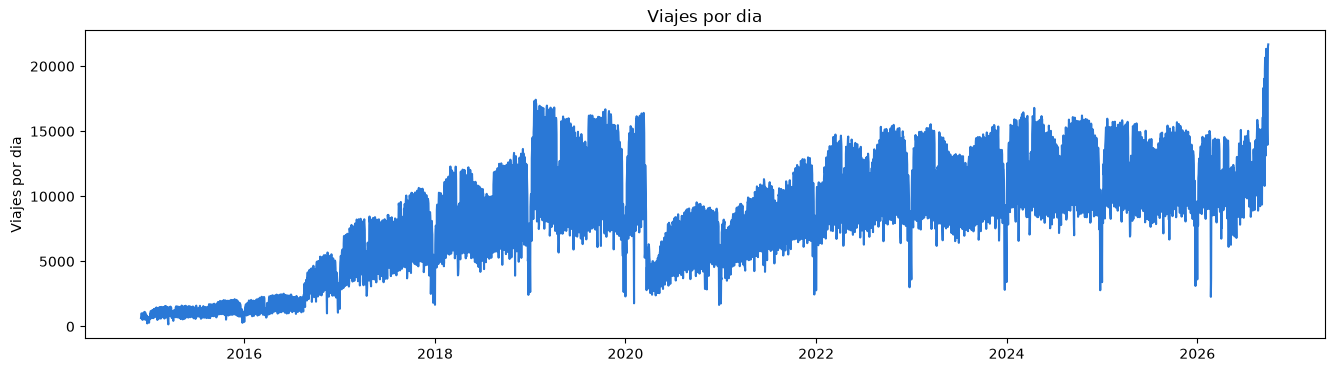

Promedio: 9,042 viajes/día | mínimo: 158 (2015-03-16) | maximo: 21,677 (2026-09-30)


In [19]:
#Cuando ocurren los viajes
por_dia = viajes.groupby(viajes["inicio"].dt.date).size()
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(pd.to_datetime(por_dia.index), por_dia.values, color=AZUL)
ax.set_ylabel("Viajes por dia")
ax.set_title("Viajes por dia")
fig.savefig(FIGURES_DIR / "eda_viajes_por_dia.png", bbox_inches="tight")
plt.show()
print(f"Promedio: {por_dia.mean():,.0f} viajes/día | mínimo: {por_dia.min():,} ({por_dia.idxmin()}) | maximo: {por_dia.max():,} ({por_dia.idxmax()})")

In [20]:
dias_es = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

tabla_dias = por_dia.rename("viajes").to_frame()
tabla_dias.index = pd.to_datetime(tabla_dias.index)
tabla_dias["dia_semana"] = [dias_es[d] for d in tabla_dias.index.dayofweek]
tabla_dias["fin_de_semana"] = tabla_dias.index.dayofweek >= 5

# Lo "normal" de cada día de la semana: la mediana del mismo día de la semana en ese mes
mes = tabla_dias.index.to_period("M")
tabla_dias["normal"] = tabla_dias.groupby([mes, "dia_semana"])["viajes"].transform("median")
tabla_dias["vs_normal_%"] = (100 * (tabla_dias["viajes"] / tabla_dias["normal"] - 1)).round(1)

# Los 15 días con menos viajes
tabla_dias.sort_values("viajes").head(50)

tabla_dias[~tabla_dias["fin_de_semana"]].sort_values("vs_normal_%").head(10)
# 02-03 de abril => Jueves y viernes santo
# 01 de mayo Dia del trabajo
# 16 de septiembre => Independencia




,viajes,dia_semana,fin_de_semana,normal,vs_normal_%
inicio,,,,,
2020-02-03,1778,Lunes,False,"15,321.50",-88.40
2015-03-16,158,Lunes,False,"1,279.00",-87.60
2020-01-01,2306,Miércoles,False,"14,423.00",-84.00
2019-01-01,2644,Martes,False,"15,467.00",-82.90
2018-01-01,1663,Lunes,False,"9,516.00",-82.50
2015-12-25,279,Viernes,False,"1,598.00",-82.50
2018-12-25,2426,Martes,False,"12,648.50",-80.80
2019-12-25,2647,Miércoles,False,"13,639.50",-80.60
2016-01-01,351,Viernes,False,"1,799.00",-80.50


In [21]:
# Dia de la semana × hora: muestra horas pico y diferencia entre laborales y fin de semana
def graficar_dia_hora(datos, titulo, archivo):
    dias = ["Lun", "Mar", "Mie", "Jue", "Vie", "Sab", "Dom"]
    tabla_dia_hora = (datos.groupby([datos["inicio"].dt.dayofweek, datos["inicio"].dt.hour]).size()
                      .unstack(fill_value=0)
                      .reindex(columns=range(24), fill_value=0))
    numero_semanas = datos["inicio"].dt.to_period("W").nunique()
    tabla_dia_hora = tabla_dia_hora / numero_semanas      # viajes promedio por semana en cada celda

    fig, ax = plt.subplots(figsize=(13, 4))
    imagen = ax.imshow(tabla_dia_hora.values, aspect="auto", cmap="Blues")
    ax.set_yticks(range(7), dias)
    ax.set_xticks(range(24), range(24))
    ax.set_xlabel("Hora de inicio")
    ax.grid(False)
    ax.set_title(titulo)
    fig.colorbar(imagen, ax=ax, label="Viajes")
    fig.savefig(FIGURES_DIR / archivo, bbox_inches="tight")
    plt.show()


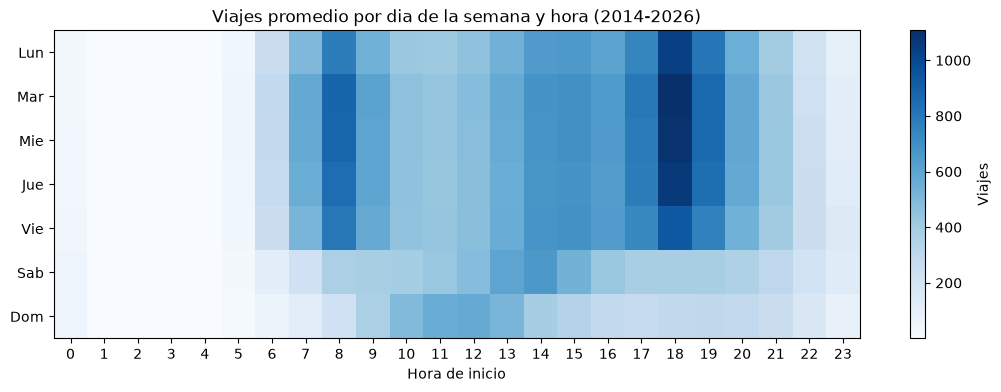

In [22]:
graficar_dia_hora(viajes, "Viajes promedio por dia de la semana y hora (2014-2026)", "eda_dia_hora.png")

In [23]:
def graficar_perfil_horario(datos, titulo, archivo):
    
    tipo_dia = np.where(datos["inicio"].dt.dayofweek >= 5, "Fin de semana", "Laboral")
    perfil = (datos.groupby([tipo_dia, datos["inicio"].dt.hour]).size()
              .unstack(0)
              .reindex(range(24), fill_value=0))
    perfil = perfil / perfil.sum() * 100

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(perfil.index, perfil["Laboral"], color=AZUL, label="Laboral")
    ax.plot(perfil.index, perfil["Fin de semana"], color=NARANJA, label="Fin de semana")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Hora de inicio")
    ax.set_ylabel("% de los viajes del tipo de día")
    ax.set_title(titulo)
    ax.legend(frameon=False)
    fig.savefig(FIGURES_DIR / archivo, bbox_inches="tight")
    plt.show()


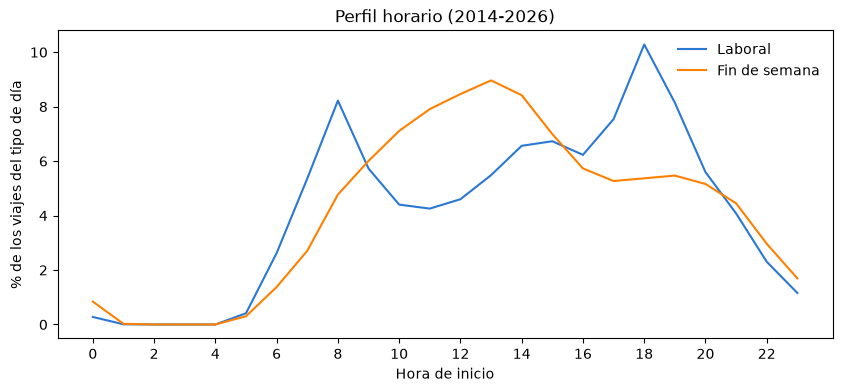

In [24]:
graficar_perfil_horario(viajes, "Perfil horario (2014-2026)", "eda_perfil_horario.png")          # Parte B

In [25]:
#Desde que estaciones
salidas = viajes["origen"].value_counts().rename("salidas")
llegadas = viajes["destino"].value_counts().rename("llegadas")

uso = pd.concat([salidas, llegadas], axis=1).fillna(0).astype(int)
uso["flujo_neto"] = uso["llegadas"] - uso["salidas"]   # >0 recibe más de lo que envía
uso = uso.join(estaciones.set_index("id")[["name", "dpcapacity", "latitude", "longitude"]])

print("Estaciones con viajes", len(uso))
print(f"Estaciones con viajes que NO estan en la nomenclatura: {uso['name'].isna().sum()}")
print(f"Estaciones de la nomenclatura SIN viajes en el rango: {(~estaciones['id'].isin(uso.index)).sum()}")
uso.sort_values("salidas", ascending=False).head(10)

Estaciones con viajes 486
Estaciones con viajes que NO estan en la nomenclatura: 3
Estaciones de la nomenclatura SIN viajes en el rango: 1


,salidas,llegadas,flujo_neto,name,dpcapacity,latitude,longitude
51,840168,1080858,240690,(GDL-049) Lopez Cotilla / Penitenciaría,39.00,20.67,-103.36
11,601481,558173,-43308,(GDL-009) Calz. Federalismo/ C. J. Angulo,23.00,20.68,-103.35
50,589311,617827,28516,(GDL-048) C. Constancio Hernández/ Av. Juaréz,23.00,20.67,-103.36
52,565185,556010,-9175,(GDL-050) C.Pedro Moreno /Federalismo,23.00,20.68,-103.35
35,562990,639231,76241,(GDL-033) Av. Hidalgo / C. Pedro Loza,15.00,20.68,-103.35
54,508272,549276,41004,(GDL-052) Av. Juarez /16 de Septiembre,23.00,20.68,-103.35
271,476322,452933,-23389,(GDL-198) Av. Alcalde / C. Hospital,31.00,20.69,-103.35
194,418011,247632,-170379,(GDL-127) Av. Vallarta / Av. de Los Arcos,19.00,20.67,-103.38
75,410594,397305,-13289,(GDL-073) Av. La Paz / Av. Federalismo,19.00,20.67,-103.36
58,365529,426219,60690,(GDL-056) Av. 16 de Sept. / C. Miguel Blanco,19.00,20.67,-103.35


In [26]:
def graficar_concentracion(datos, titulo, archivo):
    """Salidas por estacion ordenadas de mayor a menor y % que concentra el 10% mas usado."""
    salidas_ordenadas = datos["origen"].value_counts()   # ya viene de mayor a menor
    numero_top_10_pct = int(len(salidas_ordenadas) * 0.1)
    pct_salidas_top_10 = salidas_ordenadas.head(numero_top_10_pct).sum() / salidas_ordenadas.sum()
    print(f"Estaciones con salidas: {len(salidas_ordenadas)}")
    print(f"El 10% de las estaciones concentra el {pct_salidas_top_10:.0%} de las salidas")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(range(len(salidas_ordenadas)), salidas_ordenadas.values, color=AZUL, width=1.0)
    ax.set_xlabel("Estaciones (ordenadas de mas a menos usadas)")
    ax.set_ylabel("Salidas")
    ax.set_title(titulo)
    fig.savefig(FIGURES_DIR / archivo, bbox_inches="tight")
    plt.show()

Estaciones con salidas: 486
El 10% de las estaciones concentra el 39% de las salidas


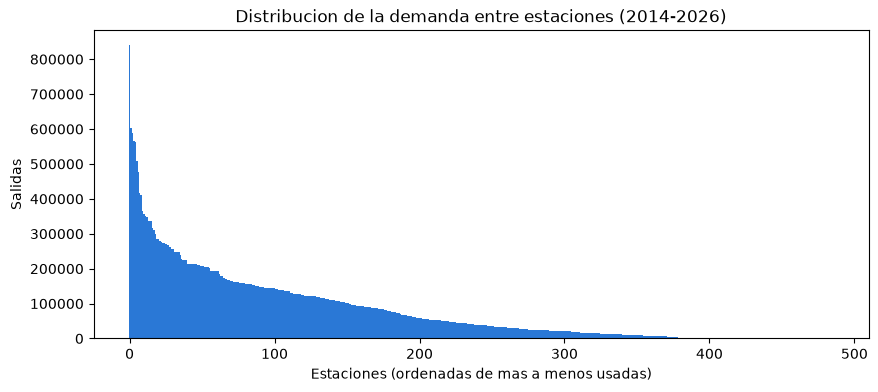

In [27]:
graficar_concentracion(viajes, "Distribucion de la demanda entre estaciones (2014-2026)", "eda_demanda_estaciones.png")

In [28]:
# Estaciones que mas envian y mas reciben (relevante para P2: rebalanceo)
print("Mas emisoras (salen mas bicis de las que llegan):")
display(uso.sort_values("flujo_neto").head(5)[["name", "salidas", "llegadas", "flujo_neto", "dpcapacity"]])
print("Mas receptoras (llegan mas bicis de las que salen):")
display(uso.sort_values("flujo_neto", ascending=False).head(5)[["name", "salidas", "llegadas", "flujo_neto", "dpcapacity"]])

Mas emisoras (salen mas bicis de las que llegan):


,name,salidas,llegadas,flujo_neto,dpcapacity
194,(GDL-127) Av. Vallarta / Av. de Los Arcos,418011,247632,-170379,19.00
197,(GDL-130) C. J. Ruíz de Alarcón / Av Vallarta,179547,123440,-56107,15.00
196,(GDL-129) C. Lope de Vega / Av. Vallarta,255794,205438,-50356,23.00
195,(GDL-128) Av. Morelos / C. Emilio Castelar,143255,99210,-44045,23.00
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,601481,558173,-43308,23.00


Mas receptoras (llegan mas bicis de las que salen):


,name,salidas,llegadas,flujo_neto,dpcapacity
51,(GDL-049) Lopez Cotilla / Penitenciaría,840168,1080858,240690,39.00
34,(GDL-032) C. Degollado / Av. Miguel Hidalgo,351556,460301,108745,15.00
56,(GDL-054) Av. Juárez / Calz. Independencia,337775,419188,81413,27.00
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,562990,639231,76241,15.00
78,(GDL-076) Calz. Revolución / C. San Fernando,154689,228033,73344,19.00


In [29]:
# Mapa: tamaño = salidas; color = emisora (naranja) o receptora (azul)
m2 = folium.Map(location=[estaciones["latitude"].mean(), estaciones["longitude"].mean()],
                zoom_start=12, tiles=ESRI, attr=ATRIBUCION)
con_coord = uso.dropna(subset=["latitude"])
escala = 15 / np.sqrt(con_coord["salidas"].max())
for est_id, e in con_coord.iterrows():
    folium.CircleMarker(
        location=[e["latitude"], e["longitude"]],
        radius=max(2, np.sqrt(e["salidas"]) * escala),
        color=NARANJA if e["flujo_neto"] < 0 else AZUL, fill=True, fill_opacity=0.6, weight=1,
        popup=f"{est_id} - {e['name']}<br>Salidas: {e['salidas']:,}<br>Llegadas: {e['llegadas']:,}",
        tooltip=e["name"],
    ).add_to(m2)
m2.save(FIGURES_DIR / "eda_uso_estaciones_mapa.html")


In [30]:
# Viajes y estaciones activas por mes 
mensual = viajes.groupby("mes_archivo", observed=True).agg(
    viajes=("origen", "size"),
    estaciones=("origen", "nunique"),
)
mensual.index = pd.PeriodIndex(mensual.index.astype(str), freq="M")
mensual["viajes_por_dia"] = (mensual["viajes"] / mensual.index.days_in_month).round(0)

# Comparación contra el mismo mes de 2019 (100% = igual que antes de la pandemia)
base_2019 = mensual.loc[mensual.index.year == 2019, "viajes_por_dia"]
base_2019.index = base_2019.index.month
mensual["%_vs_2019"] = (100 * mensual["viajes_por_dia"] / mensual.index.month.map(base_2019)).round(0)

mensual.loc["2020-01":"2023-12"]

,viajes,estaciones,viajes_por_dia,%_vs_2019
mes_archivo,,,,
2020-01,360276,274,"11,622.00",89.00
2020-02,367864,275,"12,685.00",91.00
2020-03,296759,276,"9,573.00",71.00
2020-04,129276,274,"4,309.00",36.00
2020-05,160437,274,"5,175.00",39.00
2020-06,196071,274,"6,536.00",52.00
2020-07,217858,274,"7,028.00",58.00
2020-08,230399,273,"7,432.00",58.00
2020-09,228383,273,"7,613.00",59.00


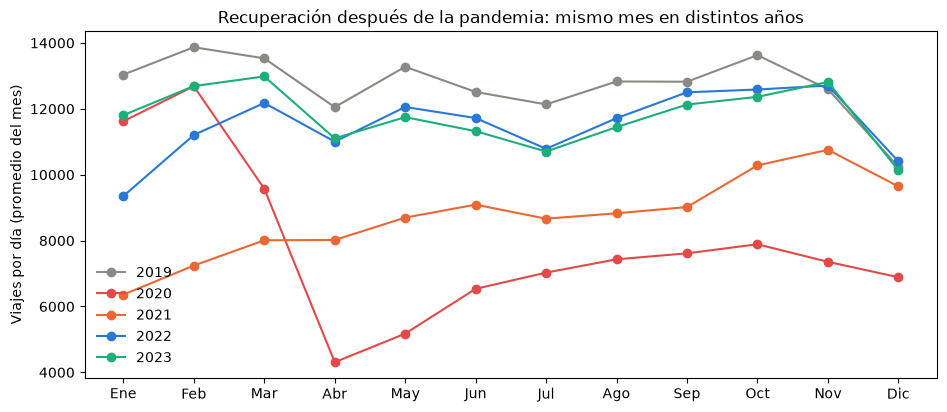

In [31]:
# Mismo mes en distintos años: una línea por año
meses_es = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
colores = {2019: "#8a8984", 2020: "#e34948", 2021: "#eb6834", 2022: "#2a78d6", 2023: "#1baf7a"}

fig, ax = plt.subplots(figsize=(11, 4.5))
for a, color in colores.items():
    serie = mensual.loc[mensual.index.year == a, "viajes_por_dia"]
    ax.plot(serie.index.month, serie.values, color=color, marker="o", label=str(a))
ax.set_xticks(range(1, 13), meses_es)
ax.set_ylabel("Viajes por día (promedio del mes)")
ax.set_title("Recuperación después de la pandemia: mismo mes en distintos años")
ax.legend(frameon=False)
fig.savefig(FIGURES_DIR / "eda_recuperacion_2019_2023.png", bbox_inches="tight")
plt.show()

In [32]:
anio = viajes["inicio"].dt.year
por_dia = viajes.groupby(viajes["inicio"].dt.normalize()).size()

por_anio = viajes.groupby(anio).agg(
    meses=("mes_archivo", "nunique"),
    viajes=("origen", "size"),
    estaciones=("origen", "nunique"),
    duracion_mediana=("duracion_min", "median"),
)
por_anio["viajes_por_dia"] = por_dia.groupby(por_dia.index.year).mean().round(0)
por_anio["var_%"] = (100 * por_anio["viajes_por_dia"].pct_change()).round(1)
por_anio

,meses,viajes,estaciones,duracion_mediana,viajes_por_dia,var_%
inicio,,,,,,
2014,1,23967,86,8.65,773.00,NaN
2015,12,469871,116,8.18,"1,287.00",66.50
2016,12,941918,241,8.63,"2,574.00",100.00
2017,12,2516534,239,9.42,"6,895.00",167.90
2018,12,3403485,277,9.43,"9,325.00",35.20
2019,12,4636652,275,9.55,"12,703.00",36.20
2020,12,2866072,276,9.63,"7,831.00",-38.40
2021,12,3184410,300,9.48,"8,724.00",11.40
2022,12,4202942,300,9.30,"11,515.00",32.00


### Conclusiones de los viajes
* Rango: diciembre de 2014 a septiembre de 2026 (142 meses), 39,078,840 viajes y 486 estaciones con viajes. Ocupan 1,290 MB en memoria.
* Calidad: sin nulos y 0% de fechas fuera de su mes. Hay 758 viajes duplicados (mismo viaje_id, inicio y origen).
* Duracion: mediana de 9.42 min y p95 de 24.12 min. El 3.11% dura menos de 1 min (95% de ellos con mismo origen y destino), 0.14% tiene duracion menor o igual a 0, 1.57% mas de 30 min y 0.04% mas de 3 h. 
* Demanda por año: crecimiento fuerte de 2014 a 2019 (de 86 a 275 estaciones y hasta 12,703 viajes por dia), caida de 38% en 2020 por la pandemia, recuperacion parcial en 2021 (+11%) y estabilidad de 2022 a 2025 (11,500 a 12,700 viajes por dia). En 2026 la red crece a 471 estaciones.
* Demanda por estacion: desde 2019 la demanda diaria total casi no crece aunque la red pasa de 275 a 471 estaciones.
* Demanda diaria: promedio de 9,042 viajes por dia en todo el historico. Minimo el 16 de marzo de 2015 (158, red en arranque) y maximo el 30 de septiembre de 2026 (21,677).

* Horarios: entre semana el pico es a las 18 h (con otro a las 8 h); el fin de semana, a las 13 h. Entre la 1 y las 4 h casi no hay viajes.
* Estaciones: el 10% de las estaciones concentra el 39% de las salidas. La mas usada es GDL-049 Lopez Cotilla / Penitenciaria (840168 salidas).
* Flujo neto: la mas emisora es GDL-127 Av. Vallarta / Av. de Los Arcos y la mas receptora es GDL-049 Lopez Cotilla / Penitenciaria.
* Cruce con la nomenclatura: 1 estacion del catalogo nunca tuvo viajes y 3 estaciones con viajes no estan en el catalogo (probablemente retiradas o renumeradas).

### 
* Limpieza: los criterios definitivos se aplican en la Parte D (duplicados, duraciones fuera de 0 a 180 min y viajes falsos con mismo origen y destino de 1 min o menos).
* Periodo: El historico muestra que antes de 2020 la red era muy distinta y estaba en formacion, y que 2020 y 2021 estan afectados por la pandemia. A partir de 2022 la demanda es estable. El equipo eligio 2024 como conjunto de estudio (train enero-septiembre, validacion octubre-noviembre, test diciembre) y reservo 2025 y 2026 para monitoreo.

* Inicio de la estabilidad: comparando cada mes con el mismo mes de 2019 (ultimo año antes de la pandemia), la demanda cae a 36% en abril de 2020 y se recupera lentamente durante 2021 (49% a 94%). En enero y febrero de 2022 vuelve a bajar (72% y 81%). A partir de marzo de 2022 todos los meses quedan entre 81% y 102% en comparacion a 2019. La red se mantiene en 300 estaciones de agosto de 2021 a septiembre de 2023, asi que la recuperacion es de demanda y no de expansion.

### Observaciones
* Estaciones nuevas en 2026: unas 100 estaciones tuvieron su primer viaje en  2026 y no tienen historia en los años de entrenamiento. Conviene evaluar el modelo por separado en estaciones existentes y nuevas o excluir las nuevas del baseline.
* Salto de septiembre de 2026: es un cambio de nivel en todo el sistema. Un modelo entrenado con datos previos subestimara la demanda posterior; esto justifica monitorear el desempeño y reentrenar.

# Parte C : Respaldo de 2024


In [33]:
ANIOS_CANDIDATOS = [2022, 2023, 2024, 2025]
mensual_candidatos = mensual[mensual.index.year.isin(ANIOS_CANDIDATOS)]

comparacion_anios = mensual_candidatos.groupby(mensual_candidatos.index.year).agg(
    meses=("viajes", "size"),
    viajes=("viajes", "sum"),
    viajes_por_dia=("viajes_por_dia", "mean"),
    estaciones_min=("estaciones", "min"),
    estaciones_max=("estaciones", "max"),
    pct_vs_2019_min=("%_vs_2019", "min"),
    pct_vs_2019_max=("%_vs_2019", "max"),
)
comparacion_anios.index.name="anio"
comparacion_anios["cambio_red"] = comparacion_anios["estaciones_max"] - comparacion_anios["estaciones_min"]
variacion_mensual = mensual_candidatos.groupby(mensual_candidatos.index.year)["viajes_por_dia"].agg(lambda s: s.std() / s.mean())

comparacion_anios["variacion_mensual_%"] = (100 * variacion_mensual).round(1)
comparacion_anios["viajes_por_dia"] = comparacion_anios["viajes_por_dia"].round(0)
comparacion_anios


,meses,viajes,viajes_por_dia,estaciones_min,estaciones_max,pct_vs_2019_min,pct_vs_2019_max,cambio_red,variacion_mensual_%
anio,,,,,,,,,
2022,12,4202942,"11,517.00",300,300,72.00,102.00,0,8.70
2023,12,4292971,"11,770.00",300,359,88.00,102.00,59,7.40
2024,12,4645921,"12,699.00",360,368,93.00,112.00,8,6.00
2025,12,4532032,"12,423.00",367,368,94.00,106.00,1,5.90


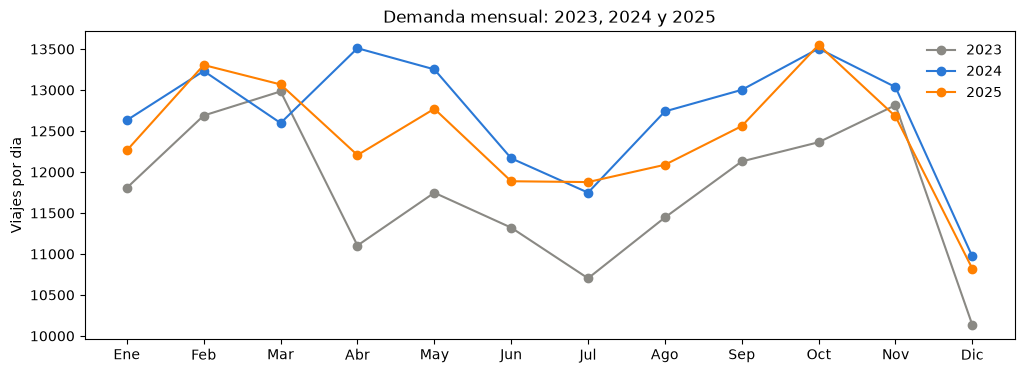

In [34]:
meses_es = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
fig, ax = plt.subplots(figsize=(12, 4))
for anio_grafica, color in {2023:GRIS, 2024: AZUL, 2025: NARANJA}.items():
    serie_anio = mensual.loc[mensual.index.year == anio_grafica]
    ax.plot(serie_anio.index.month, serie_anio["viajes_por_dia"], marker="o", color=color, label=str(anio_grafica))
ax.set_xticks(range(1, 13), meses_es)
ax.set_ylabel("Viajes por dia")
ax.set_title("Demanda mensual: 2023, 2024 y 2025")
ax.legend(frameon=False)
fig.savefig(FIGURES_DIR / "eda_2024_vs_anios_vecinos.png", bbox_inches="tight")
plt.show()

## D. Limpieza de 2024

In [35]:
viajes_anio_crudo = viajes[viajes["inicio"].dt.year == INITIAL_YEAR]
duracion_por_mes_2024 = viajes_anio_crudo.groupby(viajes_anio_crudo["inicio"].dt.month)["duracion_min"].agg(
    duracion_cero_pct=lambda d: (d <= 0).mean() * 100,
    menos_1_min_pct=lambda d: (d < 1).mean() * 100,
    duracion_mediana="median",
).round(2)
duracion_por_mes_2024

,duracion_cero_pct,menos_1_min_pct,duracion_mediana
inicio,,,
1,0.25,3.79,9.53
2,0.23,3.81,9.52
3,0.22,3.90,9.43
4,0.21,3.93,9.38
5,0.22,3.64,9.27
6,0.08,2.97,9.43
7,0.11,3.17,9.50
8,0.09,2.97,9.55
9,1.86,1.86,10.00


Criterios de limpieza 2024 (ver tabla de filtros):
* Duplicados y duraciones negativas: 0 viajes
* Duracion mayor a 180 min: 537 viajes (0.01%)
* Viajes falsos (mismo origen y destino, 1 min o menos): 143,817 viajes (3.10%); con < 1 min se escaparian 10,136
* No se filtra por duracion > 0: la mayoria de los 20,850 viajes con duracion 0 son viajes falsos y ya se quitan con el criterio de mismo origen y destino; el resto se conserva porque en sep y oct 2024 (sin segundos) son viajes validos.
* Estaciones sin capacidad o fuera del catalogo: 0 viajes en 2024 (no se aplica); revisar al usar 2025-2026

In [36]:

estaciones_con_capacidad = estaciones.loc[estaciones["dpcapacity"] > 0, "id"]
mismo_origen_destino = viajes_anio_crudo["origen"] == viajes_anio_crudo["destino"]

filtros = {
    "duplicados": viajes_anio_crudo.duplicated(subset=["viaje_id"]),
    "duracion < 0": viajes_anio_crudo["duracion_min"] < 0,
    "duracion = 0": viajes_anio_crudo["duracion_min"] == 0,
    "duracion > 180": viajes_anio_crudo["duracion_min"] > 180,
    "falsos (< 1 min)": (viajes_anio_crudo["duracion_min"] < 1) & mismo_origen_destino,
    "falsos (<= 1 min)": (viajes_anio_crudo["duracion_min"] <= 1) & mismo_origen_destino,
    "estacion sin capacidad o fuera del catalogo": ~(viajes_anio_crudo["origen"].isin(estaciones_con_capacidad)
                                                    & viajes_anio_crudo["destino"].isin(estaciones_con_capacidad)),
}
pd.DataFrame({
    "viajes_que_quita": {nombre: filtro.sum() for nombre, filtro in filtros.items()},
    "pct": {nombre: round(filtro.mean() * 100, 2) for nombre, filtro in filtros.items()},
})

,viajes_que_quita,pct
duplicados,0,0.00
duracion < 0,0,0.00
duracion = 0,20850,0.45
duracion > 180,537,0.01
falsos (< 1 min),133681,2.88
falsos (<= 1 min),143817,3.10
estacion sin capacidad o fuera del catalogo,0,0.00


In [37]:
# Limpieza de 2024 ajustada a los hallazgos del EDA
viajes_2024 = viajes[viajes["inicio"].dt.year == INITIAL_YEAR].copy()
viajes_antes_de_limpiar = len(viajes_2024)

viajes_2024 = viajes_2024.drop_duplicates(subset=["viaje_id"])
duracion_valida = viajes_2024["duracion_min"].between(0, 180)   
viaje_falso = (viajes_2024["duracion_min"] <= 1) & (viajes_2024["origen"] == viajes_2024["destino"])
viajes_2024 = viajes_2024[duracion_valida & ~viaje_falso]

print(f"Viajes {INITIAL_YEAR}: {viajes_antes_de_limpiar:,} antes | {len(viajes_2024):,} despues "
      f"| {viajes_antes_de_limpiar - len(viajes_2024):,} quitados ({1 - len(viajes_2024) / viajes_antes_de_limpiar:.2%})")



Viajes 2024: 4,645,921 antes | 4,501,567 despues | 144,354 quitados (3.11%)


## E. Analisis de 2024

In [38]:
demanda_diaria_2024 = viajes_2024.groupby(viajes_2024["inicio"].dt.normalize()).size()
tipo_dia_2024 = np.where(viajes_2024["inicio"].dt.dayofweek >= 5, "fin de semana", "laboral")
es_laboral_2024 = tipo_dia_2024 == "laboral"

print(f"Viajes 2024: {len(viajes_2024):,} | días: {demanda_diaria_2024.size}")


Viajes 2024: 4,501,567 | días: 366


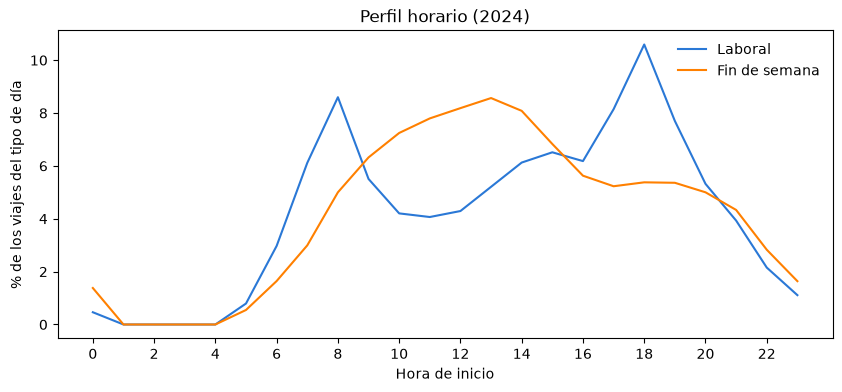

In [39]:
graficar_perfil_horario(viajes_2024, "Perfil horario (2024)", "eda_2024_perfil_horario.png")

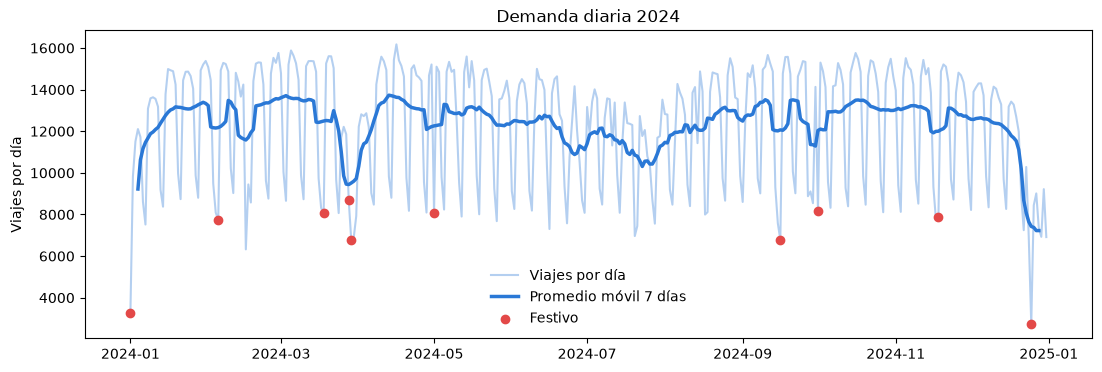

In [40]:
# Dias de descanso obligatorio
DIAS_FESTIVOS_2024 = pd.to_datetime(["2024-01-01", "2024-02-05", "2024-03-18", "2024-03-28", "2024-03-29",
                                     "2024-05-01",  "2024-09-16","2024-10-01", "2024-11-18", "2024-12-25"])
#01-01 Ano nuevo
#05-02 Dia de la constitucion
#18-03 Dia de benito juarez
#28-03 y 29-03 Jueves y viernes santo
#05-01 Dia del trabajo
#16-09 Dia de la independencia
#10-01 Transmisión del Poder Ejecutivo Federal
#18-11 Dia de la revolucion
#25-12 Navidad
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(demanda_diaria_2024.index, demanda_diaria_2024.values, color=AZUL, alpha=0.35, label="Viajes por día")
ax.plot(demanda_diaria_2024.index, demanda_diaria_2024.rolling(7, center=True).mean(),
        color=AZUL, lw=2.5, label="Promedio móvil 7 días")
festivos_con_datos = DIAS_FESTIVOS_2024[DIAS_FESTIVOS_2024.isin(demanda_diaria_2024.index)]
ax.scatter(festivos_con_datos, demanda_diaria_2024.loc[festivos_con_datos], color=ROJO, zorder=3, label="Festivo")
ax.set_ylabel("Viajes por día")
ax.set_title("Demanda diaria 2024")
ax.legend(frameon=False)
fig.savefig(FIGURES_DIR / "eda_2024_demanda_diaria.png", bbox_inches="tight")
plt.show()

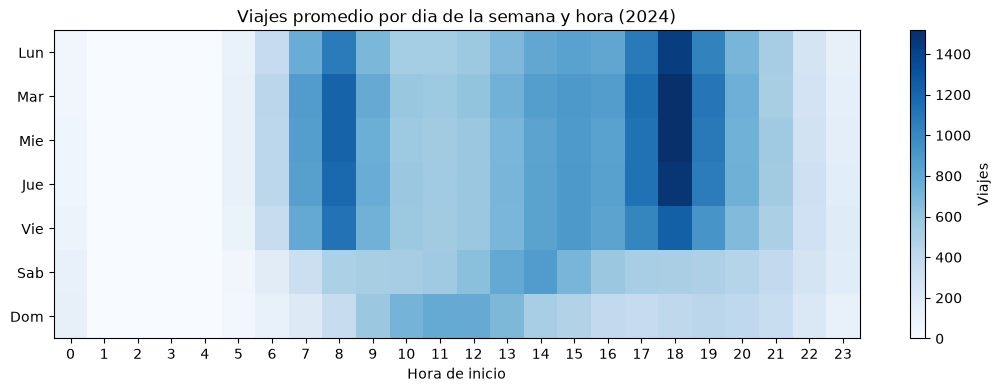

In [41]:
graficar_dia_hora(viajes_2024, "Viajes promedio por dia de la semana y hora (2024)", "eda_2024_dia_hora.png")

In [42]:
fechas_2024 = demanda_diaria_2024.index
tipo_dia_calendario_2024 = np.select(
    [fechas_2024.isin(DIAS_FESTIVOS_2024), fechas_2024.dayofweek == 5, fechas_2024.dayofweek == 6],
    ["festivo", "sabado", "domingo"], default="laboral")
demanda_diaria_2024.groupby(tipo_dia_calendario_2024).agg(["count", "mean", "median"]).round(0)

,count,mean,median
domingo,52,"8,227.00","8,265.00"
festivo,10,"6,818.00","7,813.00"
laboral,252,"13,963.00","14,426.00"
sabado,52,"9,365.00","9,551.00"


Estaciones con salidas: 370
El 10% de las estaciones concentra el 30% de las salidas


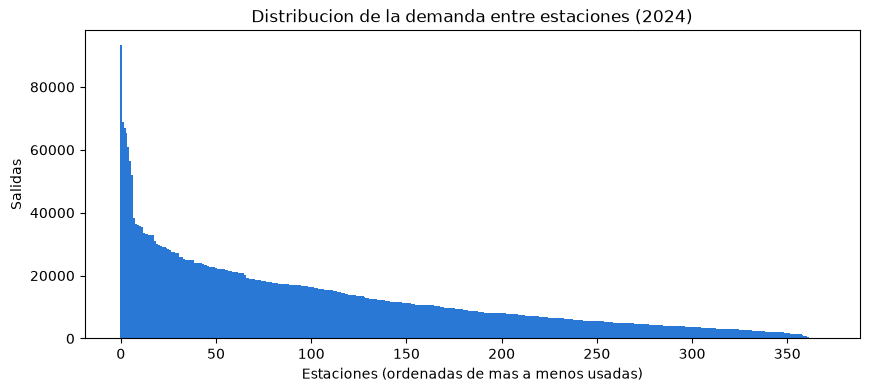

In [43]:
graficar_concentracion(viajes_2024, "Distribucion de la demanda entre estaciones (2024)", "eda_2024_demanda_estaciones.png")

In [44]:
manana_laboral_2024 = viajes_2024[es_laboral_2024 & viajes_2024["inicio"].dt.hour.isin([7, 8, 9])]
dias_laborales_2024 = manana_laboral_2024["inicio"].dt.normalize().nunique()

balance_manana = pd.DataFrame({
    "salidas": manana_laboral_2024["origen"].value_counts(),
    "llegadas": manana_laboral_2024["destino"].value_counts(),
}).fillna(0)
balance_manana["llegadas_menos_salidas"] = balance_manana["llegadas"] - balance_manana["salidas"]
balance_manana["neto_por_dia"] = (balance_manana["llegadas_menos_salidas"] / dias_laborales_2024).round(1)
balance_manana = balance_manana.join(estaciones.set_index("id")[["name", "dpcapacity"]])

print(f"Dias laborales 2024: {dias_laborales_2024}")
display(balance_manana.nsmallest(5, "neto_por_dia"))   # se vacian en la manana
display(balance_manana.nlargest(5, "neto_por_dia"))    # se llenan en la manana

Dias laborales 2024: 262


,salidas,llegadas,llegadas_menos_salidas,neto_por_dia,name,dpcapacity
51,25780,7130,-18650,-71.20,(GDL-049) Lopez Cotilla / Penitenciaría,39
11,13292,7827,-5465,-20.90,(GDL-009) Calz. Federalismo/ C. J. Angulo,23
52,10092,6037,-4055,-15.50,(GDL-050) C.Pedro Moreno /Federalismo,23
38,8087,4394,-3693,-14.10,(GDL-036) C. Marcos Castellanos/ C. Morelos,23
69,7620,4471,-3149,-12.00,(GDL-067) Calzada Federalismo / C. Vidrio,19


,salidas,llegadas,llegadas_menos_salidas,neto_por_dia,name,dpcapacity
34,2970,12007,9037,34.50,(GDL-032) C. Degollado / Av. Miguel Hidalgo,15
35,4598,11211,6613,25.20,(GDL-033) Av. Hidalgo / C. Pedro Loza,15
42,1239,6449,5210,19.90,(GDL-040) C. Morelos / C. Progreso,19
65,2140,7120,4980,19.00,(GDL-063) C. Colonias / C. López Cotilla,27
160,2284,6843,4559,17.40,(GDL-093) C. H Colegio Militar / Av. Américas,15


In [45]:
viajes_2024["inicio"].dt.hour.value_counts().reindex(range(6), fill_value=0) 

inicio
0    29255
1       11
2        0
3        0
4        0
5    33489
Name: count, dtype: int64

## Decisiones para feature engineering

1. Entrenar con 2024 fue una decision del equipo, pues es el anio mas completo (4,645,921 viajes, 12 meses, sin duplicados) y su forma mensual se parece a 2025.
2. Usar el dia de la semana sin juntar sabado y domingo. Un dia laboral tiene 14,426 viajes, un sabado 9,551, un domingo 8,265 y un festivo 7813 (medianas). Puede ser un valor por dia (0 a 6) o cuatro categorias: laboral, sabado, domingo y festivo. La forma depende del modelo: los arboles usan bien el 0 a 6; los lineales necesitan las categorias en columnas 0/1.
3. Combinar la hora con el tipo de dia. Cada tipo de dia tiene su hora pico: laboral 8 h y 18 h, sabado 14 h, domingo 11 h. Los modelos de arboles aprenden esta combinacion solos; los lineales necesitan una columna hora por tipo de dia.
4. Agregar una bandera de vacaciones en lugar de usar el mes. La demanda baja en las vacaciones de Semana Santa, de verano y de diciembre, y Semana Santa cambia de fecha cada anio (en 2024 fue en marzo), por lo que el mes no captura bien estas caidas.
5. Incluir la estacion en el modelo. Las estaciones son muy distintas entre si: el 10% de ellas concentra el 30% de las salidas, por lo que el modelo necesita saber de que estacion se trata. Si P1 se predice por hora o por bloques de horas, excluir de 1 a 4 h: en 2024 hubo 11 viajes a la 1 h y 0 de 2 a 4 h.
6. Para P2, calcular llegadas menos salidas por franja horaria, no por dia completo. De 7 a 9 h en dias laborales de 2024, GDL-049 pierde 71 bicis por dia y tiene 39 espacios, y GDL-032 recibe 34.5 por dia con solo 15 espacios. En el total del dia estos desbalances se compensan y el riesgo no se ve.
7. Preparar una solucion para las estaciones nuevas de 2026. En 2024 hubo 370 estaciones activas; en 2026 hay 484, y 100 de ellas no tienen historial para entrenar. Para esas estaciones se puede usar su zona o su capacidad y suponer que se comportan como estaciones parecidas.
8. Quitar viajes falsos con mismo origen y destino y duracion de 1 minuto o menos, no solo con duracion menor a 1 minuto. Septiembre y octubre de 2024 vienen sin segundos: antes de limpiar, el 1.86% de sus viajes tenia duracion 0 (vs 0.04% a 0.25% en otros meses), casi todos viajes falsos. Con este criterio se quitan 143,817 viajes.